In [ ]:
import tensorflow as tf

In [ ]:
(train_images, train_labels),  (test_images, test_labels) = tf.keras.datasets.mnist.load_data()

train_images = train_images.reshape(train_images.shape[0], 28, 28, 1)
train_images = (train_images - 127.5) / 127.5

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
SHUFFLE_SIZE = 60000
BATCH_SIZE  = 256

train_ds = tf.data.Dataset.from_tensor_slices(train_images)
train_ds = train_ds.shuffle(SHUFFLE_SIZE).batch(BATCH_SIZE)

In [ ]:
from tensorflow.keras.layers import Dense, Conv2D, LeakyReLU, Dropout, Flatten


D = tf.keras.Sequential([
    Conv2D(64, (5, 5), strides=(2,2), padding="same", input_shape=[28, 28, 1]),
    LeakyReLU(),
    Dropout(0.3),

    Conv2D(128, (5,5), strides=(2,2), padding="same"),
    LeakyReLU(),
    Dropout(0.3),

    Flatten(),
    Dense(1, activation="sigmoid")
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
from tensorflow.keras.layers import BatchNormalization, Reshape, Conv2DTranspose


G = tf.keras.Sequential([
    Dense(7*7*256, use_bias=False, input_shape=(100,)),
    BatchNormalization(),
    LeakyReLU(),

    Reshape((7, 7, 256)),
    Conv2DTranspose(128, (5, 5), strides=(1, 1), padding="same", use_bias = False),
    BatchNormalization(),
    LeakyReLU(),

    Conv2DTranspose(64, (5, 5), strides=(2, 2), padding="same", use_bias = False),
    BatchNormalization(),
    LeakyReLU(),

    Conv2DTranspose(1, (5, 5), strides=(2, 2), padding="same", use_bias = False),

])

G.output_shape

/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


(None, 28, 28, 1)

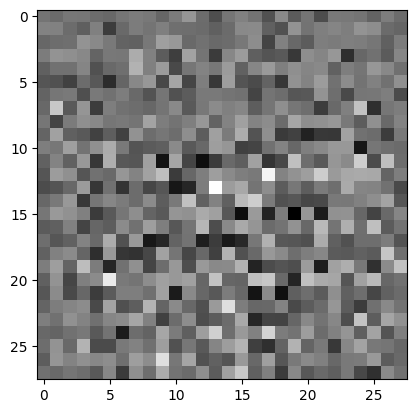

In [ ]:
import matplotlib.pyplot as plt
noise = tf.random.normal([1, 100])

generated_image = G(noise, training=False)

plt.imshow(generated_image[0, :, :, 0], cmap='gray')

In [ ]:
decision = D(generated_image)
print(decision)

tf.Tensor([[0.49960425]], shape=(1, 1), dtype=float32)


In [ ]:
def discriminator_loss(real_output, fake_output):
    # real_output = discriminator(real_image)
    # fake_output = discriminator(generated_image)

    cross_entropy = tf.keras.losses.BinaryCrossentropy()
    # Minimize loss such that:
    # Real Images are predicted 1 by discriminator
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    # Fake Images are predicted 0 by discriminator
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)

    total_loss = real_loss + fake_loss
    return total_loss

def generator_loss(fake_output):
    # fake_output = discriminator(fake_image)

    # Train Generator such that Images are predicted 1 by discriminator
    cross_entropy = tf.keras.losses.BinaryCrossentropy()
    return cross_entropy(tf.ones_like(fake_output), fake_output)

In [ ]:
generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

In [ ]:
@tf.function
def train_step(images, generator=G, discriminator=D,
               generator_loss=generator_loss,
               discriminator_loss=discriminator_loss,
                generator_opimizer=generator_optimizer,
               discriminator_optimizer=discriminator_optimizer,
               noise_dim = 100):

    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape ,tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images)
        fake_output = discriminator(generated_images)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    # Apply gradients
    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

In [ ]:
import matplotlib.pyplot as plt

def generate_and_save_images(model, epoch, test_input):
    # (batch_size, 100)
    prediction = model(test_input)
    # (batch_size, 28, 28, 1)
    plt.figure(figsize=(4,4))

    for i in range(prediction.shape[0]):
        plt.subplot(4, 4, i+1)
        plt.imshow(prediction[i, :, :, 0], cmap='gray')
        plt.axis('off')

    plt.savefig(f'image_at_epoch_{epoch}.png')
    plt.show()

In [ ]:
EPOCHS = 50
noise_dim = 100
num_samples_to_plot = 16

seed = tf.random.normal([num_samples_to_plot, noise_dim])
# random data of shape [16, 100]

In [ ]:
from IPython import display
import time

def train(dataset, epochs, G, seed):
    for epoch in range(epochs):
        start = time.time()
        for img_batch in dataset:
            train_step(img_batch)

            display.clear_output(wait=True)
            generate_and_save_images(G, epoch, seed)
        end = time.time()
        print(f'Time for epoch {epoch} = {end-start}')
    display.clear_output(wait=True)
    generate_and_save_images(G, epoch, seed)


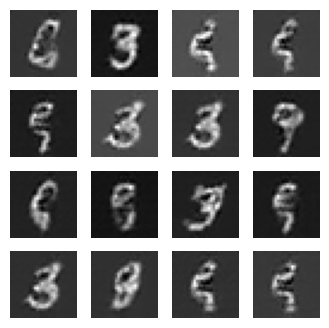

In [ ]:
train(train_ds, EPOCHS, G, seed)